In [1]:
# Qui merite le Ballon d'Or 2026 ?
# On prend les 5 attaquants les mieux cotes chez les bookmakers, les criteres
# officiels du reglement, et on regarde qui gagne selon ce qu'on decide de peser.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soccerdata as sd

pd.set_option("display.max_columns", 80)

[10/27/26 01:44:24] INFO     No custom team name replacements found. You can configure these in       ]8;id=12721579;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_config.py\_config.py]8;;\:]8;id=12721580;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_config.py#91\91]8;;\
                             /Users/nathanpariente/soccerdata/config/teamname_replacements.json.                   

                    INFO     Custom league dict loaded from                                          ]8;id=12721586;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_config.py\_config.py]8;;\:]8;id=12721587;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_config.py#187\187]8;;\
                             /Users/nathanpariente/soccerdata/config/league_dict.json.                             

In [2]:
# Nos candidats : les 5 attaquants les mieux cotes chez les bookmakers
# au 22/09/26 (capture dans docs/). Deux precisions sur le perimetre :
# - profils offensifs uniquement, car nos indicateurs (buts, xG, creation)
#   ne permettent pas de comparer equitablement un milieu ou un defenseur ;
# - Messi, bien cote, est ecarte : il joue en MLS, hors de nos sources de
#   donnees - on ne classe pas ce qu'on ne peut pas mesurer pareil.

CANDIDATS = [
    "Khvicha Kvaratskhelia",
    "Ousmane Dembélé",
    "Lamine Yamal",
    "Kylian Mbappé",
    "Harry Kane",
]

In [3]:
# Les stats individuelles de la saison 2025-26.
# Notre version de la bibliotheque expose 5 tableaux ; 'standard' contient
# deja buts, passes decisives, minutes et xG - on verifie ce qu'on a avant
# d'aller chercher plus loin.
fbref = sd.FBref(leagues="Big 5 European Leagues Combined", seasons="2025-2026")

stats_std  = fbref.read_player_season_stats(stat_type="standard")   # le socle
stats_tirs = fbref.read_player_season_stats(stat_type="shooting")   # tirs, xG
stats_disc = fbref.read_player_season_stats(stat_type="misc")       # cartons

print(stats_std.shape, stats_tirs.shape, stats_disc.shape)

                    INFO     Saving cached data to /Users/nathanpariente/soccerdata/data/FBref       ]8;id=12721594;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_common.py\_common.py]8;;\:]8;id=12721595;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_common.py#250\250]8;;\

(2839, 21) (2839, 15) (2839, 17)


In [4]:
# La Coupe du monde 2026 compte dans la periode d'eligibilite (art. 3 des critères du BO 2026).
cdm = sd.FBref(leagues="INT-World Cup", seasons="2026")
cdm_std = cdm.read_player_season_stats(stat_type="standard")
print(cdm_std.shape)

[10/27/26 01:44:34] INFO     Saving cached data to /Users/nathanpariente/soccerdata/data/FBref       ]8;id=12721600;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_common.py\_common.py]8;;\:]8;id=12721601;file:///Users/nathanpariente/Documents/ballon-dor-2026/.venv/lib/python3.12/site-packages/soccerdata/_common.py#250\250]8;;\

(1039, 22)


In [5]:
# Les colonnes FBref sont a deux etages.
# On les aplatit en noms simples et on ne garde que ce qui sert au projet.
def aplatir(table):
    t = table.reset_index()
    t.columns = ["_".join(str(p) for p in c).strip("_ ") if isinstance(c, tuple) else str(c)
                 for c in t.columns]
    return t

COLS = {
    "Playing Time_MP":  "matchs",
    "Playing Time_Min": "minutes",
    "Performance_Gls":  "buts",
    "Performance_Ast":  "passes_d",
    "Performance_PK":   "pen_marques",
    "Performance_CrdY": "jaunes",
    "Performance_CrdR": "rouges",
}

def extraire(table, source):
    t = aplatir(table)
    t = t[t["player"].isin(CANDIDATS)][["player"] + list(COLS)].rename(columns=COLS)
    for c in COLS.values():
        t[c] = pd.to_numeric(t[c], errors="coerce").fillna(0)
    t["source"] = source
    return t

champ = extraire(stats_std, "championnat")
champ

,player,matchs,minutes,buts,passes_d,pen_marques,jaunes,rouges,source
659,Lamine Yamal,28,2262,16,11,3,1,0,championnat
1020,Kylian Mbappé,31,2599,25,5,8,4,0,championnat
1611,Khvicha Kvaratskhelia,28,1479,8,4,1,1,0,championnat
1621,Ousmane Dembélé,22,1063,10,7,2,0,0,championnat
2370,Harry Kane,31,2377,36,5,10,1,0,championnat


In [6]:
# Meme extraction sur la CDM. Kvaratskhelia n'y figure pas : la Georgie
# n'etait pas qualifiee. Sa ligne CDM vaut zero
cdm_5 = extraire(cdm_std, "cdm")
cdm_5

,player,matchs,minutes,buts,passes_d,pen_marques,jaunes,rouges,source
377,Harry Kane,7,652,6,1,2,0,0,cdm
400,Kylian Mbappé,8,695,10,4,1,1,0,cdm
409,Ousmane Dembélé,8,592,6,2,0,0,0,cdm
872,Lamine Yamal,8,614,1,0,0,0,0,cdm


In [7]:
# La bibliotheque ne couvre pas la Ligue des champions (voir sa liste de
# competitions valides). Les lignes 2025-26 de nos cinq viennent donc de
# FBref aussi, mais relevees a la main sur les pages joueurs et verifiees.
# Volumes uniquement : les par-90 seront recalcules sur les totaux.
LDC = pd.DataFrame([
    # joueur,                 matchs, minutes, buts, passes_d, pen, jaunes, rouges
    ["Khvicha Kvaratskhelia", 16,     1134,    10,   6,        0,   3,      0],
    ["Ousmane Dembélé",       13,      823,     8,   2,        2,   0,      0],
    ["Lamine Yamal",          10,      871,     6,   4,        3,   4,      0],
    ["Harry Kane",            13,     1036,    14,   2,        4,   0,      0],
    ["Kylian Mbappé",         11,      912,    15,   1,        3,   2,      0],
], columns=["player", "matchs", "minutes", "buts", "passes_d",
            "pen_marques", "jaunes", "rouges"])
LDC["source"] = "ldc"
LDC

,player,matchs,minutes,buts,passes_d,pen_marques,jaunes,rouges,source
0,Khvicha Kvaratskhelia,16,1134,10,6,0,3,0,ldc
1,Ousmane Dembélé,13,823,8,2,2,0,0,ldc
2,Lamine Yamal,10,871,6,4,3,4,0,ldc
3,Harry Kane,13,1036,14,2,4,0,0,ldc
4,Kylian Mbappé,11,912,15,1,3,2,0,ldc


In [8]:
# Championnat + CDM + LdC : la saison complete au sens de l'article 3.
# On additionne les volumes par joueur, puis on recalcule les par-90
saison = pd.concat([champ, cdm_5, LDC], ignore_index=True)

volumes = ["matchs", "minutes", "buts", "passes_d", "pen_marques", "jaunes", "rouges"]
totaux = saison.groupby("player", as_index=False)[volumes].sum()

totaux["n90"] = totaux["minutes"] / 90
totaux["buts_hors_pen"] = totaux["buts"] - totaux["pen_marques"]
totaux["buts_hp_p90"] = totaux["buts_hors_pen"] / totaux["n90"]
totaux["ga_hp_p90"] = (totaux["buts_hors_pen"] + totaux["passes_d"]) / totaux["n90"]
# les cartons en negatif doux : un rouge pese comme trois jaunes
totaux["cartons_p90"] = (totaux["jaunes"] + 3 * totaux["rouges"]) / totaux["n90"]

totaux.sort_values("ga_hp_p90", ascending=False).round(2)

,player,matchs,minutes,buts,passes_d,pen_marques,jaunes,rouges,n90,buts_hors_pen,buts_hp_p90,ga_hp_p90,cartons_p90
4,Ousmane Dembélé,43,2478,24,11,4,0,0,27.53,20,0.73,1.13,0.0
0,Harry Kane,51,4065,56,8,16,1,0,45.17,40,0.89,1.06,0.02
2,Kylian Mbappé,50,4206,50,10,12,7,0,46.73,38,0.81,1.03,0.15
1,Khvicha Kvaratskhelia,44,2613,18,10,1,4,0,29.03,17,0.59,0.93,0.14
3,Lamine Yamal,46,3747,23,15,6,5,0,41.63,17,0.41,0.77,0.12


In [9]:
# --- Critere 2 : performances collectives et palmares (art. 4.2) ---
# Lecture a la lettre de l'article 3 : compte tout trophee gagne dans la
# fenetre officielle (3 aout 2025 - 19 juillet 2026), quelle que soit la
# saison qu'il recompense. La colonne supercoupes somme celles de la fenetre
# (Supercoupe UEFA aout 2025, supercoupes nationales).
# Valeurs : 1 vainqueur, 0.5 finaliste, 0.25 3e CDM, 0.15 4e CDM.
PALMARES = pd.DataFrame([
    # joueur,                 champ., coupe_nat, supercoupes, ldc, cdm
    ["Khvicha Kvaratskhelia", 1,      0,         2,           1,   0],     # Supercoupe UEFA + Trophee des Champions Janvier 2026
    ["Ousmane Dembélé",       1,      0,         2,           1,   0.15],  # idem ; France 4e en CDM
    ["Lamine Yamal",          1,      0,         1,           0,   1],     # Supercoupe d'Espagne 2026
    ["Harry Kane",            1,      1,         1,           0,   0.25],  # Supercoupe d'Allemagne Aout 2025 ; Angleterre 3e
    ["Kylian Mbappé",         0,      0,         0,           0,   0.15],  # France 4e en CDM
], columns=["player", "championnat", "coupe_nat", "supercoupes", "ldc", "cdm"])

# Bareme de valeur des trophees. Choix assume et discutable
BAREME = {"championnat": 3, "coupe_nat": 1, "supercoupes": 0.5, "ldc": 5, "cdm": 6}
PALMARES["palmares_pts"] = sum(PALMARES[t] * v for t, v in BAREME.items())

# --- Distinctions individuelles : rattachees au critere 1 (art. 4.1),
# elles mesurent le "caractere decisif et impressionnant" reconnu.
# 2 pts = meilleur joueur d'une competition majeure ; 1 pt = meilleur
# buteur ou passeur d'une competition ; 1.5 pt = soulier d'or europeen.
DISTINCTIONS = pd.DataFrame([
    ["Khvicha Kvaratskhelia", 2.0],   # meilleur joueur de la LdC
    ["Ousmane Dembélé",       2.0],   # meilleur joueur de Ligue 1
    ["Lamine Yamal",          3.0],   # joueur de la saison Liga + meilleur passeur Liga
    ["Harry Kane",            2.5],   # meilleur buteur Bundesliga + soulier d'or europeen
    ["Kylian Mbappé",         3.0],   # meilleur buteur CDM + LdC + Liga
], columns=["player", "distinctions"])

bilan = totaux.merge(PALMARES[["player", "palmares_pts"]], on="player") \
              .merge(DISTINCTIONS, on="player")
bilan[["player", "palmares_pts", "distinctions"]]

,player,palmares_pts,distinctions
0,Harry Kane,6.0,2.5
1,Khvicha Kvaratskhelia,9.0,2.0
2,Kylian Mbappé,0.9,3.0
3,Lamine Yamal,9.5,3.0
4,Ousmane Dembélé,9.9,2.0


In [10]:
# Chaque indicateur est ramene entre 0 et 1 par min-max SUR NOS CINQ :
# le meilleur du groupe vaut 1, le moins bon 0. On classe entre eux
def norm(s):
    return (s - s.min()) / (s.max() - s.min()) if s.max() > s.min() else s * 0

# Critere 1 : production reelle (volume ET par-90) + distinctions.
# Le volume recompense la saison pleine, le par-90 l'efficacite.
IND_1 = ["buts_hors_pen", "passes_d", "buts_hp_p90", "ga_hp_p90", "distinctions"]
bilan["crit_individuel"] = sum(norm(bilan[c]) for c in IND_1) / len(IND_1)

# Critere 2 : le palmares.
bilan["crit_collectif"] = norm(bilan["palmares_pts"])

# Critere 3 : moins de cartons = mieux, d'ou le 1 moins.
bilan["crit_fairplay"] = 1 - norm(bilan["cartons_p90"])

# Scenario central : notre lecture de la hierarchie officielle.
# Le reglement donne un ORDRE (1 > 2 > 3), pas des poids chiffres -
# la cellule suivante fait varier tous les poids compatibles.
POIDS = {"crit_individuel": 0.60, "crit_collectif": 0.30, "crit_fairplay": 0.10}
bilan["score"] = sum(bilan[c] * w for c, w in POIDS.items())

bilan[["player", "crit_individuel", "crit_collectif", "crit_fairplay", "score"]] \
    .sort_values("score", ascending=False).round(3)

,player,crit_individuel,crit_collectif,crit_fairplay,score
4,Ousmane Dembélé,0.445,1.000,1.0,0.667
0,Harry Kane,0.665,0.567,0.852,0.654
3,Lamine Yamal,0.4,0.956,0.198,0.546
2,Kylian Mbappé,0.754,0.000,0.0,0.452
1,Khvicha Kvaratskhelia,0.222,0.900,0.08,0.411


In [11]:
# L'article 4 impose seulement un ordre : individuel > collectif > fair-play.
# On enumere toutes les ponderations qui le respectent (pas de 5 %) et on
# compte qui finit premier sous chacune.
grille = []
pas = 0.05
for w3 in np.arange(0.0, 0.35, pas):
    for w2 in np.arange(w3 + pas, 0.50, pas):
        w1 = round(1 - w2 - w3, 2)
        if w1 <= w2:
            continue
        s = (w1 * bilan["crit_individuel"] + w2 * bilan["crit_collectif"]
             + w3 * bilan["crit_fairplay"])
        grille.append([w1, round(w2, 2), round(w3, 2),
                       bilan.loc[s.idxmax(), "player"]])

grille = pd.DataFrame(grille, columns=["individuel", "collectif", "fairplay", "premier"])
print(len(grille), "ponderations admissibles")
print(grille["premier"].value_counts(normalize=True).round(2))

35 ponderations admissibles
premier
Ousmane Dembélé    0.54
Harry Kane         0.40
Kylian Mbappé      0.06
Name: proportion, dtype: float64


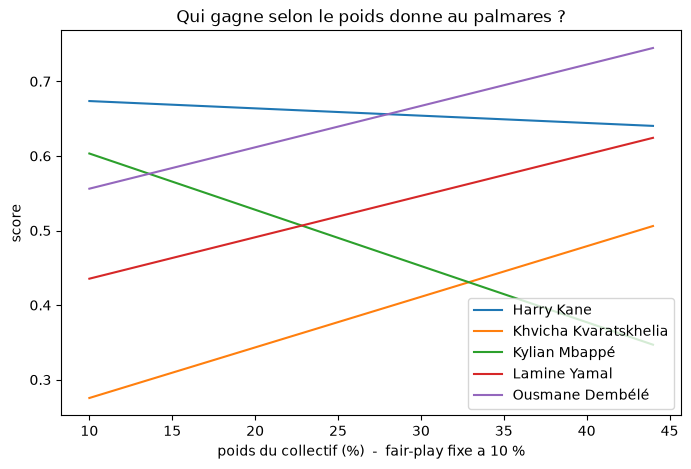

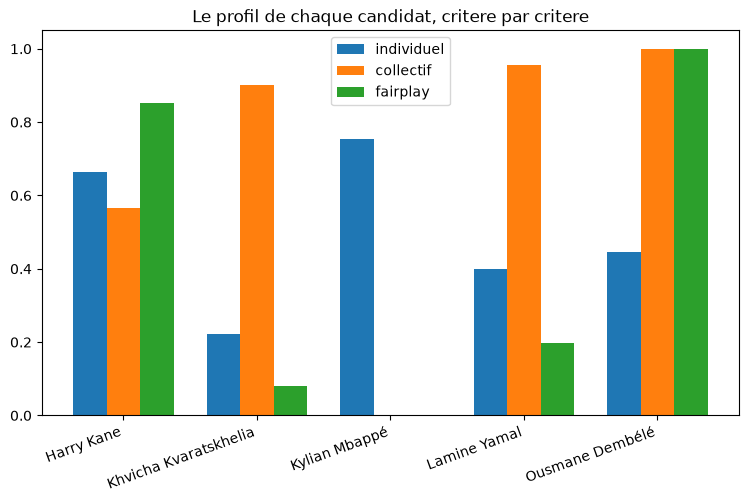

In [12]:
# Graphique 1 : le score de chacun quand on fait glisser le curseur
# individuel/collectif, fair-play fixe a 10 %.
fig, ax = plt.subplots(figsize=(8, 5))
w2_axe = np.arange(0.10, 0.45, 0.01)
for _, r in bilan.iterrows():
    scores = [(1 - w2 - 0.10) * r["crit_individuel"] + w2 * r["crit_collectif"]
              + 0.10 * r["crit_fairplay"] for w2 in w2_axe]
    ax.plot(w2_axe * 100, scores, label=r["player"])
ax.set_xlabel("poids du collectif (%)  -  fair-play fixe a 10 %")
ax.set_ylabel("score")
ax.set_title("Qui gagne selon le poids donne au palmares ?")
ax.legend()
fig.savefig("../figures/sensibilite.png", dpi=150, bbox_inches="tight")

# Graphique 2 : les trois criteres cote a cote, joueur par joueur.
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(bilan))
for i, c in enumerate(["crit_individuel", "crit_collectif", "crit_fairplay"]):
    ax.bar(x + (i - 1) * 0.25, bilan[c], width=0.25,
           label=c.replace("crit_", ""))
ax.set_xticks(x, bilan["player"], rotation=20, ha="right")
ax.set_title("Le profil de chaque candidat, critere par critere")
ax.legend()
fig.savefig("../figures/profils.png", dpi=150, bbox_inches="tight")

In [13]:
# 26 octobre 2026
# Classement officiel du Ballon d'Or
# On garde nos cinq candidats avec leur rang parmi les 30 nommes.
JURY = pd.DataFrame([
    ["Harry Kane", 1],
    ["Kylian Mbappé", 2],
    ["Lamine Yamal", 3],
    ["Khvicha Kvaratskhelia", 6],
    ["Ousmane Dembélé", 7],
], columns=["player", "rang_jury"])

# L'ordre des cotes bookmakers au 22/09 (capture dans docs/).
MARCHE = ["Harry Kane", "Lamine Yamal", "Kylian Mbappé",
          "Khvicha Kvaratskhelia", "Ousmane Dembélé"]

verdict = bilan[["player", "score"]].copy()
verdict["rang_modele"] = verdict["score"].rank(ascending=False).astype(int)
verdict["rang_marche"] = verdict["player"].map({p: i + 1 for i, p in enumerate(MARCHE)})
verdict = verdict.merge(JURY, on="player")
verdict["rang_jury_parmi_5"] = verdict["rang_jury"].rank().astype(int)

verdict.sort_values("rang_jury")[["player", "rang_jury", "rang_jury_parmi_5",
                                  "rang_marche", "rang_modele"]]

,player,rang_jury,rang_jury_parmi_5,rang_marche,rang_modele
0,Harry Kane,1,1,1,2
2,Kylian Mbappé,2,2,3,4
3,Lamine Yamal,3,3,2,3
1,Khvicha Kvaratskhelia,6,4,4,5
4,Ousmane Dembélé,7,5,5,1


In [14]:
# Qui a le mieux "vu" le vote ? On mesure l'accord entre deux classements
# avec la correlation de Spearman : +1 = meme ordre, 0 = aucun lien,
# -1 = ordre inverse. C'est la correlation classique, calculee sur les rangs.
def accord(a, b):
    return a.rank().corr(b.rank())

print("Bookmakers (22 sept.) :", round(accord(verdict["rang_marche"], verdict["rang_jury_parmi_5"]), 2))
print("Notre score 60/30/10  :", round(accord(verdict["rang_modele"], verdict["rang_jury_parmi_5"]), 2))

Bookmakers (22 sept.) : 0.9
Notre score 60/30/10  : -0.1


In [15]:
# On retourne le probleme : parmi les 35 lectures du reglement de la
# cellule 11, laquelle ressemble le plus au vrai vote ? On rejoue la
# meme grille et on mesure l'accord de chaque lecture avec le jury.
rang_jury = bilan["player"].map(dict(zip(verdict["player"], verdict["rang_jury_parmi_5"])))

lectures = []
for w3 in np.arange(0.0, 0.35, 0.05):
    for w2 in np.arange(w3 + 0.05, 0.50, 0.05):
        w1 = round(1 - w2 - w3, 2)
        if w1 <= w2:
            continue
        s = (w1 * bilan["crit_individuel"] + w2 * bilan["crit_collectif"]
             + w3 * bilan["crit_fairplay"])
        lectures.append([w1, round(w2, 2), round(w3, 2), accord(-s, rang_jury)])

lectures = pd.DataFrame(lectures, columns=["individuel", "collectif", "fairplay", "accord_jury"])
print(lectures.sort_values("accord_jury", ascending=False).head(5).round(2).to_string(index=False))
print("\nMeilleur accord possible avec le reglement :", round(lectures["accord_jury"].max(), 2))

 individuel  collectif  fairplay  accord_jury
       0.85       0.10      0.05          0.7
       0.85       0.15      0.00          0.7
       0.80       0.20      0.00          0.7
       0.80       0.15      0.05          0.7
       0.95       0.05      0.00          0.6

Meilleur accord possible avec le reglement : 0.7


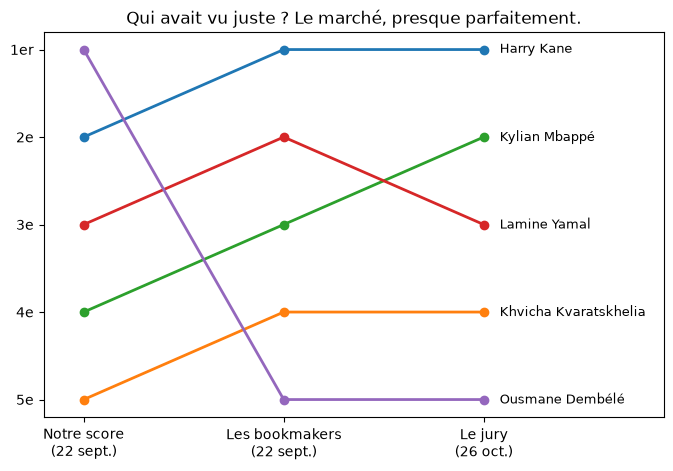

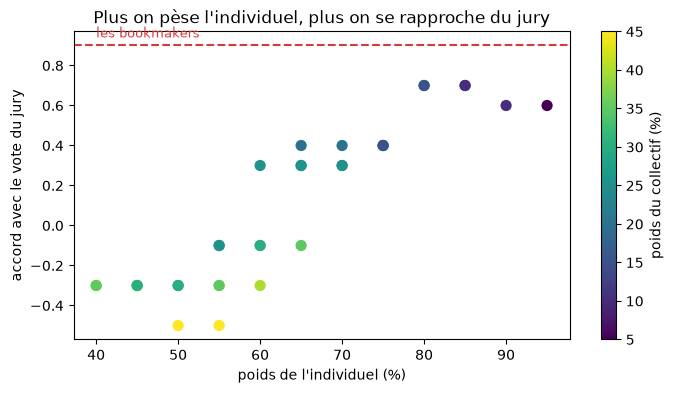

In [16]:
# Visuel 1 : trois classements cote a cote, une ligne par joueur.
fig, ax = plt.subplots(figsize=(8, 5))
colonnes = ["rang_modele", "rang_marche", "rang_jury_parmi_5"]
titres = ["Notre score\n(22 sept.)", "Les bookmakers\n(22 sept.)", "Le jury\n(26 oct.)"]
for _, r in verdict.iterrows():
    ax.plot(range(3), [r[c] for c in colonnes], marker="o", lw=2)
    ax.text(2.08, r["rang_jury_parmi_5"], r["player"], va="center", fontsize=9)
ax.set_xticks(range(3), titres)
ax.set_yticks(range(1, 6), ["1er", "2e", "3e", "4e", "5e"])
ax.invert_yaxis()
ax.set_xlim(-0.2, 2.9)
ax.set_title("Qui avait vu juste ? Le marché, presque parfaitement.")
fig.savefig("../figures/verdict.png", dpi=150, bbox_inches="tight")
plt.show()

# Visuel 2 : l'accord de chaque lecture du reglement avec le jury.
marche = accord(verdict["rang_marche"], verdict["rang_jury_parmi_5"])
fig, ax = plt.subplots(figsize=(8, 4))
pts = ax.scatter(lectures["individuel"] * 100, lectures["accord_jury"],
                 c=lectures["collectif"] * 100, cmap="viridis", s=50)
ax.axhline(marche, color="#d63b3b", ls="--", lw=1.5)
ax.text(lectures["individuel"].min() * 100, marche + 0.04, "les bookmakers", color="#d63b3b", fontsize=9)
fig.colorbar(pts, ax=ax, label="poids du collectif (%)")
ax.set_xlabel("poids de l'individuel (%)")
ax.set_ylabel("accord avec le vote du jury")
ax.set_title("Plus on pèse l'individuel, plus on se rapproche du jury")
fig.savefig("../figures/lectures_jury.png", dpi=150, bbox_inches="tight")
plt.show()